### Proyek Klasifikasi Kanker Payudara (Breast Cancer Classification)
Proyek ini membandingkan dua algoritma pembelajaran mesin untuk mengklasifikasikan kanker payudara menjadi Jinak (Benign) atau Ganas (Malignant).

**Algoritma yang digunakan:**
1. Logistic Regression
2. Random Forest Classifier

**Metrik Evaluasi:**
* Accuracy
* Precision
* Recall
* F1-score
* Confusion Matrix

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [29]:
# 1. Load Dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print(f"Ukuran Dataset: {X.shape}")
print(f"Distribusi Kelas (0 = Malignant, 1 = Benign):\n{pd.Series(y).value_counts()}")
display(X.head())

Ukuran Dataset: (569, 30)
Distribusi Kelas (0 = Malignant, 1 = Benign):
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


/tmp/ipykernel_2296/3486631361.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=y, palette='Set2')


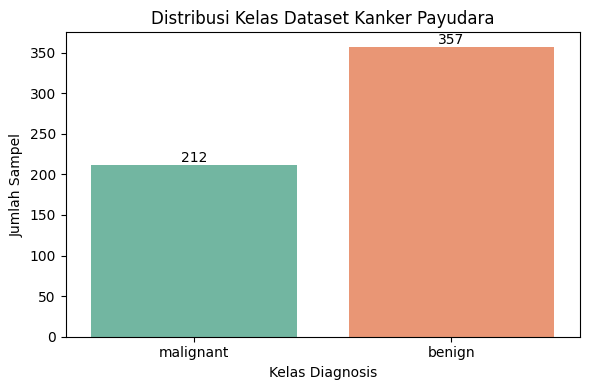

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi Distribusi Kelas
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=y, palette='Set2')

# Mengatur label dan judul
plt.xticks(ticks=[0, 1], labels=data.target_names)
plt.xlabel('Kelas Diagnosis')
plt.ylabel('Jumlah Sampel')
plt.title('Distribusi Kelas Dataset Kanker Payudara')

# Menambahkan nilai di atas setiap bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

In [31]:
# 2. Split Data dan Standarisasi Fitur
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [32]:
# 3. Inisialisasi dan Pelatihan Model
lr_model = LogisticRegression(random_state=42)
rf_model = RandomForestClassifier(random_state=42)

lr_model.fit(X_train_scaled, y_train)
rf_model.fit(X_train_scaled, y_train)

# Prediksi
y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test_scaled)

In [33]:
# 4. Evaluasi dan Perbandingan Metrik
metrics = {
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Logistic Regression': [
        accuracy_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_lr)
    ],
    'Random Forest': [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf)
    ]
}

df_performance = pd.DataFrame(metrics)
display(df_performance)

,Metrik,Logistic Regression,Random Forest
0,Accuracy,0.982456,0.956140
1,Precision,0.986111,0.958904
2,Recall,0.986111,0.972222
3,F1-Score,0.986111,0.965517


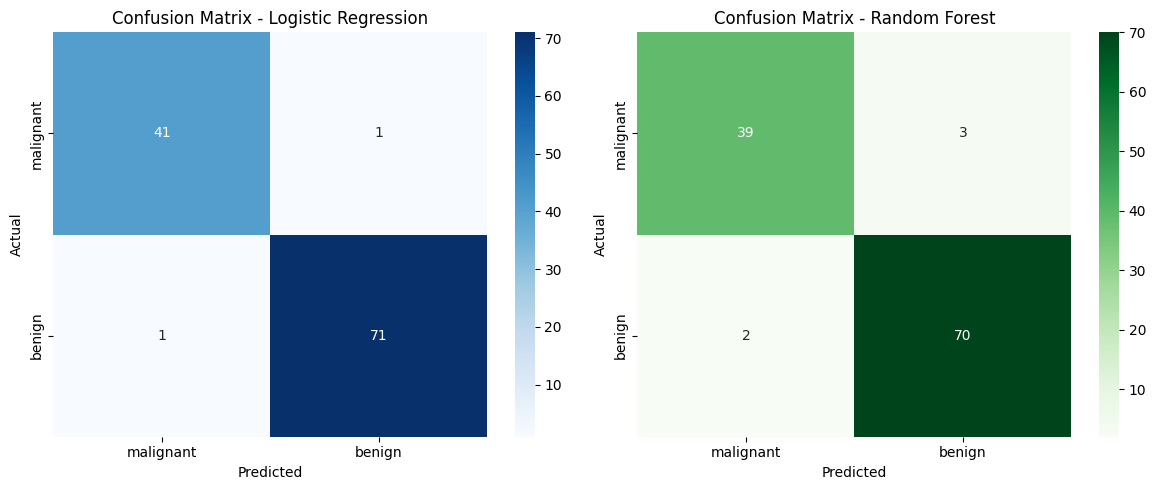

In [34]:
# 5. Visualisasi Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix - Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=data.target_names, yticklabels=data.target_names)
axes[0].set_title('Confusion Matrix - Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Confusion Matrix - Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=data.target_names, yticklabels=data.target_names)
axes[1].set_title('Confusion Matrix - Random Forest')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

### Kesimpulan Hasil Eksperimen
Silakan jalankan sel-sel di atas terlebih dahulu untuk menganalisis hasil performa dari kedua algoritma klasifikasi secara langsung. Secara umum:
* **Logistic Regression** bekerja sangat baik pada data yang terstandarisasi linear.
* **Random Forest** mampu menangkap hubungan non-linear yang kompleks antar fitur tanpa memerlukan penskalaan yang ketat.
* Analisis nilai **Recall** sangat krusial dalam domain medis ini untuk meminimalkan potensi kesalahan diagnosis negatif palsu (False Negative).